# Interpretable Biodegradability Screening — Results

Companion to `reports/biodegradability_report.pdf`: every table and figure behind the report, plus
ROC curves, the OCT-H depth trade-off, and the additive kernel model's effect curves.

**What is compared.** Nine models on the stratified split: the development set (train + validation,
844 chemicals, 559 NRB / 285 RB) with the same stratified 5 folds for every model, at four descriptor
budgets (k = 3, 5, 10, all 41). NRB = 1. Settings are chosen by mean cross-validated AUC; every number
here is **out-of-fold** — the 211 test chemicals have not been used.

| Group | Models | Source |
|---|---|---|
| Flexible | random forest, XGBoost, kernel logistic, Nadaraya–Watson | `src/python/strat_models.py` |
| Readable | additive kernel (Σ s_j ≤ k), OCT-H | `src/julia/strat_additive_kernel.jl`, `src/julia/strat_oct_h.jl` |
| Readable | ridge logistic, OCT, CART | `MLProjectPart1_Orig.ipynb` |

**Data.** The notebook reads a snapshot in `reports/results/` so it runs without re-fitting anything
(only NumPy, pandas and Matplotlib are needed). To refresh it after re-running the models, copy the
files from `outputs/strat/` (see `reports/results/README.md`). CART / OCT / ridge-logistic summary numbers
are copied from the Part 1 notebook's outputs; ridge logistic's out-of-fold scores are recomputed below
with that notebook's exact algorithm.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "reports").is_dir() else Path.cwd().parent
RES = ROOT / "reports" / "results"
DATA = ROOT / "data"

SETS = ["k3", "k5", "k10", "all"]
SET_LABEL = {"k3": "k = 3", "k5": "k = 5", "k10": "k = 10", "all": "all 41"}
FLEXIBLE = ["Random forest", "XGBoost", "Kernel logistic", "Nadaraya-Watson"]
READABLE = ["Additive kernel", "Ridge logistic", "OCT-H", "OCT", "CART"]
MODELS = FLEXIBLE + READABLE

# Fixed identity colors (categorical slots 1-4, never cycled); flexible models are the gray reference.
COLOR = {"Ridge logistic": "#2a78d6", "Additive kernel": "#eb6834", "OCT-H": "#1baf7a", "OCT": "#eda100",
         "reference": "#8a8984"}
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": TEXT,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
pd.set_option("display.precision", 3)

## 1. Load the results

In [2]:
ours = pd.read_csv(RES / "cv_results_all_models.csv")
ours["model"] = ours["model"].replace({"Nadaraya-Watson": "Nadaraya-Watson"})
part1 = pd.read_csv(RES / "notebook_models_cv.csv")
cols = ["set", "model", "cv_auc", "cv_auc_sd", "cv_bal_acc", "prec_rb_cleared", "leaves", "descriptors_used"]
res = pd.concat([ours[cols], part1[cols]], ignore_index=True)
assert set(res["model"]) == set(MODELS), set(res["model"]) ^ set(MODELS)

def table(value, fmt="{:.3f}"):
    t = res.pivot(index="model", columns="set", values=value).loc[MODELS, SETS]
    t.columns = [SET_LABEL[s] for s in SETS]
    return t

print(f"{len(res)} rows: {res['model'].nunique()} models x {res['set'].nunique()} descriptor budgets")

36 rows: 9 models x 4 descriptor budgets


## 2. Ranking quality: cross-validated AUC

Mean AUC over the 5 folds (± one standard deviation across folds). Flexible models first, readable
models below. Differences smaller than about one fold-to-fold spread (±0.01–0.04) are not reliable.

In [3]:
auc = table("cv_auc")
sd = table("cv_auc_sd")
auc.map("{:.3f}".format) + " ± " + sd.map("{:.3f}".format)

,k = 3,k = 5,k = 10,all 41
model,,,,
Random forest,0.855 ± 0.015,0.917 ± 0.014,0.932 ± 0.009,0.942 ± 0.011
XGBoost,0.851 ± 0.019,0.915 ± 0.016,0.924 ± 0.016,0.941 ± 0.010
Kernel logistic,0.849 ± 0.020,0.910 ± 0.023,0.929 ± 0.013,0.943 ± 0.017
Nadaraya-Watson,0.840 ± 0.018,0.891 ± 0.021,0.910 ± 0.012,0.915 ± 0.011
Additive kernel,0.878 ± 0.022,0.904 ± 0.019,0.919 ± 0.011,0.936 ± 0.012
Ridge logistic,0.830 ± 0.011,0.881 ± 0.027,0.910 ± 0.015,0.931 ± 0.012
OCT-H,0.806 ± 0.031,0.866 ± 0.028,0.866 ± 0.026,0.875 ± 0.035
OCT,0.792 ± 0.018,0.842 ± 0.025,0.830 ± 0.020,0.834 ± 0.020
CART,0.819 ± 0.015,0.809 ± 0.039,0.823 ± 0.019,0.828 ± 0.038


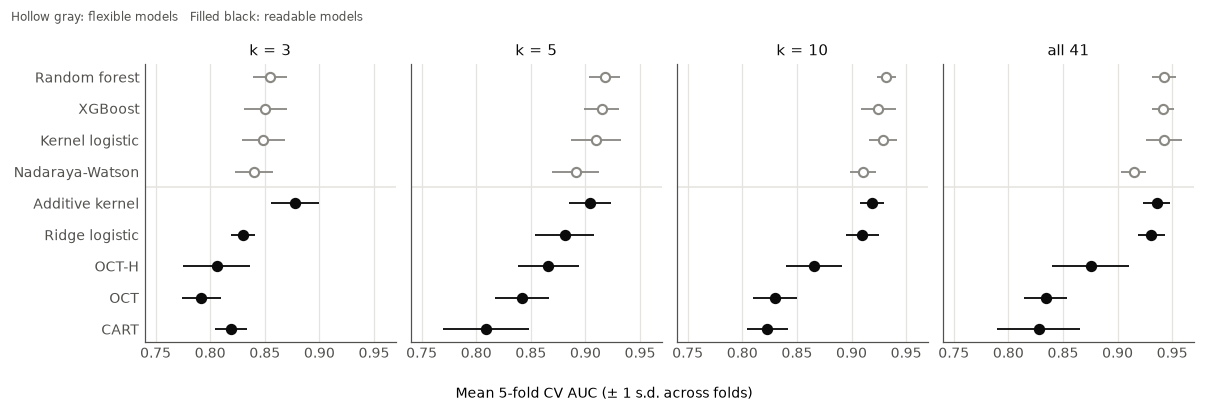

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.6), sharey=True)
ypos = np.arange(len(MODELS))[::-1]
for ax, s in zip(axes, SETS):
    for y, m in zip(ypos, MODELS):
        r = res[(res.set == s) & (res.model == m)].iloc[0]
        flexible = m in FLEXIBLE
        ax.errorbar(r.cv_auc, y, xerr=r.cv_auc_sd, fmt="o", ms=6, capsize=0, lw=1.2,
                    color="#8a8984" if flexible else TEXT,
                    mfc="white" if flexible else TEXT, mew=1.4)
    ax.axhline(len(READABLE) - 0.5, color=GRID, lw=1)
    ax.set_title(SET_LABEL[s], fontsize=10, color=TEXT)
    ax.set_xlim(0.74, 0.97)
    ax.grid(axis="y", visible=False)
    ax.tick_params(length=0)
axes[0].set_yticks(ypos, MODELS)
fig.supxlabel("Mean 5-fold CV AUC (± 1 s.d. across folds)", fontsize=9)
fig.text(0.01, 0.97, "Hollow gray: flexible models   Filled black: readable models", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 3. The price of readability

The best flexible model at each budget (random forest, XGBoost or kernel logistic, all on the fixed
descriptor lists) is the ceiling; the gap below it is what readability costs. This is Figure 1 of the report.

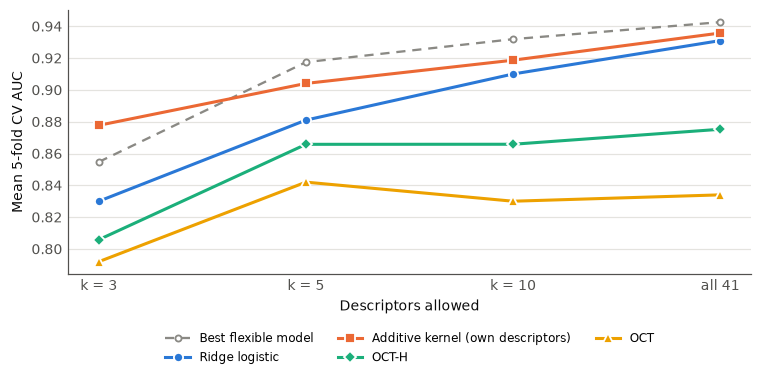

AUC gap to the flexible ceiling (negative = above it):


,k = 3,k = 5,k = 10,all 41
model,,,,
Additive kernel,-0.023,0.013,0.013,0.007
Ridge logistic,0.025,0.036,0.022,0.012
OCT-H,0.049,0.052,0.066,0.067
OCT,0.063,0.075,0.102,0.109
CART,0.036,0.108,0.109,0.115


In [5]:
ceiling = table("cv_auc").loc[["Random forest", "XGBoost", "Kernel logistic"]].max()
x = np.arange(len(SETS))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(x, ceiling.values, color=COLOR["reference"], lw=1.5, ls=(0, (4, 3)), marker="o", ms=4,
        mfc="white", mec=COLOR["reference"], mew=1.2, label="Best flexible model")
for m, marker in [("Ridge logistic", "o"), ("Additive kernel", "s"), ("OCT-H", "D"), ("OCT", "^")]:
    ax.plot(x, table("cv_auc").loc[m].values, color=COLOR[m], lw=2, marker=marker, ms=6,
            mec="white", mew=1.2, label=m + (" (own descriptors)" if m == "Additive kernel" else ""))
ax.set_xticks(x, [SET_LABEL[s] for s in SETS])
ax.set_xlabel("Descriptors allowed")
ax.set_ylabel("Mean 5-fold CV AUC")
ax.grid(axis="x", visible=False)
ax.tick_params(length=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

gap = (ceiling - table("cv_auc").loc[READABLE]).round(3)
gap.columns = [SET_LABEL[s] for s in SETS]
print("AUC gap to the flexible ceiling (negative = above it):")
gap

## 4. Screening view: catching 90% of persistent chemicals

Each model's threshold is set (on out-of-fold scores) so that it catches at least 90% of NRB
chemicals. The table counts the **RB chemicals it still clears correctly, out of 285** — higher means
fewer unnecessary lab tests.

In [6]:
cleared = table("prec_rb_cleared").astype(int)
cleared

,k = 3,k = 5,k = 10,all 41
model,,,,
Random forest,157,216,216,233
XGBoost,148,217,218,232
Kernel logistic,156,209,221,239
Nadaraya-Watson,155,202,212,224
Additive kernel,184,208,217,226
Ridge logistic,157,179,223,226
OCT-H,125,210,210,219
OCT,126,167,190,149
CART,105,175,177,186


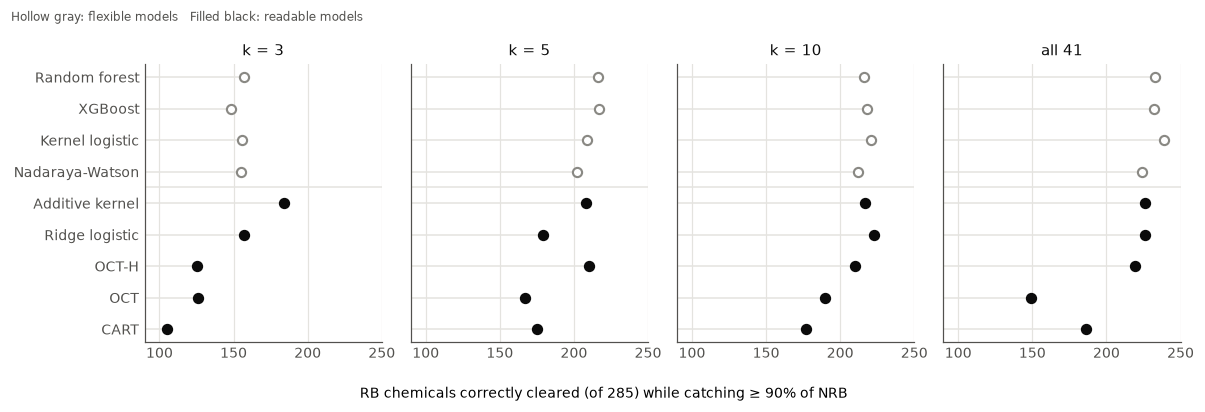

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.6), sharey=True)
for ax, s in zip(axes, SETS):
    for y, m in zip(ypos, MODELS):
        v = cleared.loc[m, SET_LABEL[s]]
        flexible = m in FLEXIBLE
        ax.plot([0, v], [y, y], color=GRID, lw=1, zorder=1)
        ax.plot(v, y, "o", ms=6, color="#8a8984" if flexible else TEXT,
                mfc="white" if flexible else TEXT, mew=1.4, zorder=2)
    ax.axhline(len(READABLE) - 0.5, color=GRID, lw=1)
    ax.set_title(SET_LABEL[s], fontsize=10, color=TEXT)
    ax.set_xlim(90, 250)
    ax.grid(axis="y", visible=False)
    ax.tick_params(length=0)
axes[0].set_yticks(ypos, MODELS)
fig.supxlabel("RB chemicals correctly cleared (of 285) while catching ≥ 90% of NRB", fontsize=9)
fig.text(0.01, 0.97, "Hollow gray: flexible models   Filled black: readable models", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 5. Balanced accuracy and tree size

Balanced accuracy (mean of NRB recall and RB specificity) at each model's balanced threshold, and the
number of leaves in each final tree.

In [8]:
ba = table("cv_bal_acc")
leaves = table("leaves").loc[["OCT-H", "OCT", "CART"]].astype(int)
display(ba.round(3))
leaves

,k = 3,k = 5,k = 10,all 41
model,,,,
Random forest,0.791,0.839,0.851,0.871
XGBoost,0.787,0.837,0.839,0.865
Kernel logistic,0.788,0.836,0.848,0.875
Nadaraya-Watson,0.778,0.817,0.840,0.861
Additive kernel,0.799,0.831,0.849,0.863
Ridge logistic,0.763,0.806,0.844,0.868
OCT-H,0.769,0.822,0.821,0.842
OCT,0.774,0.813,0.788,0.789
CART,0.787,0.771,0.785,0.812


,k = 3,k = 5,k = 10,all 41
model,,,,
OCT-H,6,7,5,4
OCT,6,9,8,9
CART,6,5,6,7


## 6. ROC curves (out-of-fold)

Out-of-fold scores exist for every model fitted in this project. For ridge logistic regression they are
recomputed here with the Part 1 notebook's algorithm (Newton's method, intercept unpenalized,
descriptors standardized per training fold, λ from the notebook), and the AUCs are checked against
its reported values. CART and OCT out-of-fold scores were not saved, so they are not shown.

In [9]:
def read_part(name):
    d = pd.read_csv(DATA / f"biodeg_{name}_strat.xls", sep=";", header=None)
    return d.iloc[:, :41].to_numpy(float), (d.iloc[:, 41].str.strip() == "NRB").to_numpy(int)

Xtr, ytr = read_part("train"); Xva, yva = read_part("val")
X_dev, y_dev = np.vstack([Xtr, Xva]), np.concatenate([ytr, yva])
fold = pd.read_csv(RES / "cv_folds.csv").sort_values("dev_row")["fold"].to_numpy()
fs_tbl = pd.read_csv(RES / "feature_sets.csv")
DESCRIPTORS = fs_tbl[fs_tbl.set == "all"].sort_values("order")["descriptor"].tolist()
feature_idx = {s: [DESCRIPTORS.index(c) for c in fs_tbl[fs_tbl.set == s].sort_values("order")["descriptor"]]
               for s in SETS}

def auc(p, y):
    pos, neg = p[y == 1], p[y == 0]
    return ((pos[:, None] > neg).sum() + 0.5 * (pos[:, None] == neg).sum()) / (len(pos) * len(neg))

def ridge_logit(Z, y, lam, iters=100):
    A = np.hstack([np.ones((len(Z), 1)), Z])
    P = np.diag([0.0] + [lam] * Z.shape[1])
    b = np.zeros(A.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-A @ b))
        step = np.linalg.solve(A.T @ (A * (p * (1 - p))[:, None]) + P, A.T @ (y - p) - P @ b)
        b += step
        if np.linalg.norm(step) < 1e-8:
            break
    return b

LAMBDA = {"k3": 1.0, "k5": 10.0, "k10": 1.0, "all": 1.0}   # chosen by CV in the Part 1 notebook
oof = {}
for s in SETS:
    cols, p, aucs = feature_idx[s], np.zeros(len(y_dev)), []
    for f in range(1, 6):
        tr, va = fold != f, fold == f
        mu, sd_ = X_dev[tr][:, cols].mean(0), np.maximum(X_dev[tr][:, cols].std(0, ddof=1), 1e-12)
        b = ridge_logit((X_dev[tr][:, cols] - mu) / sd_, y_dev[tr].astype(float), LAMBDA[s])
        p[va] = 1 / (1 + np.exp(-(b[0] + ((X_dev[va][:, cols] - mu) / sd_) @ b[1:])))
        aucs.append(auc(p[va], y_dev[va]))
    oof[("Ridge logistic", s)] = p
    print(f"{SET_LABEL[s]:<7} ridge logistic CV AUC {np.mean(aucs):.3f}  (Part 1 notebook: "
          f"{part1[(part1.set == s) & (part1.model == 'Ridge logistic')].cv_auc.iloc[0]:.3f})")

files = {"Random forest": "random_forest", "XGBoost": "xgboost", "Kernel logistic": "kernel_logistic",
         "Nadaraya-Watson": "nadaraya_watson", "Additive kernel": "additive_kernel", "OCT-H": "oct_h"}
for m, f in files.items():
    t = pd.read_csv(RES / f"oof_{f}.csv").sort_values("dev_row")
    assert (t["fold"].to_numpy() == fold).all()
    for s in SETS:
        oof[(m, s)] = t[f"score_nrb_{s}"].to_numpy()

k = 3   ridge logistic CV AUC 0.830  (Part 1 notebook: 0.830)
k = 5   ridge logistic CV AUC 0.881  (Part 1 notebook: 0.881)
k = 10  ridge logistic CV AUC 0.910  (Part 1 notebook: 0.910)
all 41  ridge logistic CV AUC 0.931  (Part 1 notebook: 0.931)


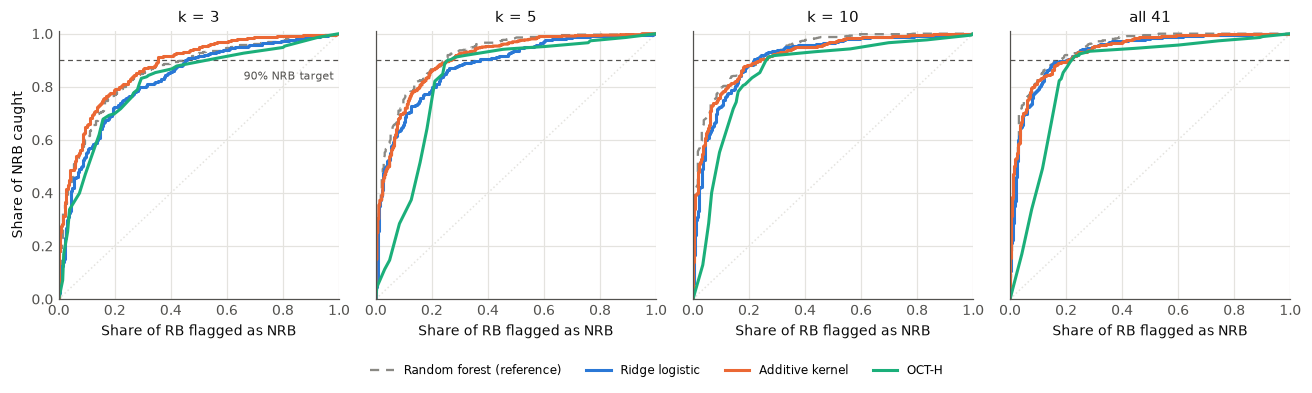

In [10]:
def roc(p, y):
    ts = np.unique(p)[::-1]
    return (np.r_[0, [(p[y == 0] >= t).mean() for t in ts], 1],
            np.r_[0, [(p[y == 1] >= t).mean() for t in ts], 1])

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), sharey=True)
for j, (ax, s) in enumerate(zip(axes, SETS)):
    ax.plot([0, 1], [0, 1], color=GRID, lw=1, ls=":")
    ax.axhline(0.9, color=MUTED, lw=0.8, ls=(0, (4, 3)))
    fpr, tpr = roc(oof[("Random forest", s)], y_dev)
    ax.plot(fpr, tpr, color=COLOR["reference"], lw=1.5, ls=(0, (4, 3)), label="Random forest (reference)")
    for m in ["Ridge logistic", "Additive kernel", "OCT-H"]:
        fpr, tpr = roc(oof[(m, s)], y_dev)
        ax.plot(fpr, tpr, color=COLOR[m], lw=2, label=m)
    ax.set_title(SET_LABEL[s], fontsize=10, color=TEXT)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
    ax.set_xlabel("Share of RB flagged as NRB")
    ax.tick_params(length=0)
axes[0].set_ylabel("Share of NRB caught")
axes[0].text(0.98, 0.86, "90% NRB target", ha="right", va="top", fontsize=7.5, color=MUTED)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

OCT-H's curve is made of straight segments: a tree has one score per leaf, so its threshold moves
in leaf-sized steps. Where a curve crosses the dashed 90% line, further left means fewer RB chemicals
sent for unnecessary tests.

## 7. OCT-H: what each extra level of depth buys

For each depth, the best minimum leaf size by mean CV AUC, and the average number of leaves across
folds. Budgets are an ordered quantity, so they share one hue from light (k = 3) to dark (all 41).

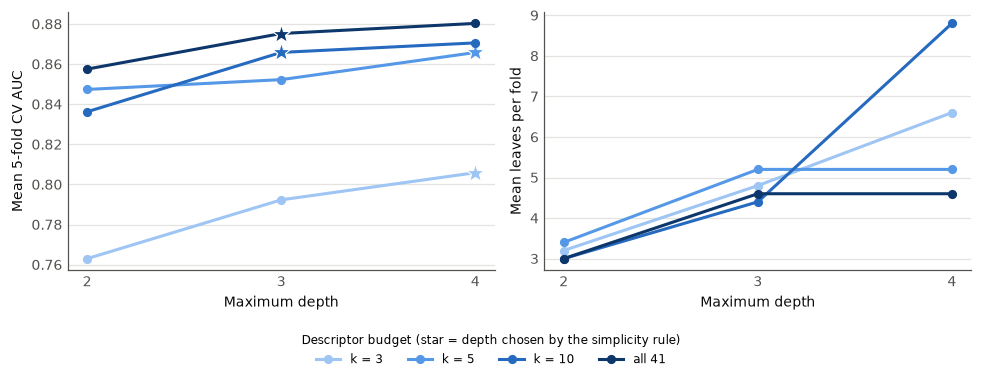

In [11]:
dc = pd.read_csv(RES / "oct_h_depth_curve.csv")
ramp = {"k3": "#9ec5f4", "k5": "#5598e7", "k10": "#256abf", "all": "#0d366b"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4))
for s in SETS:
    d = dc[dc.set == s].sort_values("max_depth")
    a1.plot(d.max_depth, d.cv_auc, color=ramp[s], lw=2, marker="o", ms=5, label=SET_LABEL[s])
    ch = d[d.chosen]
    a1.plot(ch.max_depth, ch.cv_auc, marker="*", ms=13, color=ramp[s], mec="white", mew=0.8, ls="none")
    a2.plot(d.max_depth, d.mean_leaves, color=ramp[s], lw=2, marker="o", ms=5)
a1.set(xlabel="Maximum depth", ylabel="Mean 5-fold CV AUC", xticks=[2, 3, 4])
a2.set(xlabel="Maximum depth", ylabel="Mean leaves per fold", xticks=[2, 3, 4])
for a in (a1, a2):
    a.grid(axis="x", visible=False); a.tick_params(length=0)
handles, labels = a1.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.02),
           title="Descriptor budget (star = depth chosen by the simplicity rule)", title_fontsize=8)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

## 8. The additive kernel model

It predicts from a sum of one smooth curve per descriptor, P(NRB) = σ(b + Σ_j f_j(x_j)), and chooses at
most k descriptors itself (binaries s_j with Σ s_j ≤ k) inside every CV fold.

**Which descriptors it picks.** The selection from each fold's training rows, and the final choice on
all 844 chemicals. At k = 3 every search was proven optimal and all five folds agree; at k = 5 three of
five folds match the final choice, and at k = 10 the choices vary (the searches there stop with about
16% and 8% optimality gaps, so the subsets are good but not proven best).

In [12]:
sel = pd.read_csv(RES / "additive_kernel_selected.csv")
sel = sel[sel.set != "all"].copy()
sel["descriptors"] = sel["descriptors"].str.replace(" | ", ", ", regex=False)
sel.pivot(index="fold", columns="set", values="descriptors")[["k3", "k5", "k10"]]

set,k3,k5,k10
fold,,,
1,"SpMax_L, SpPosA_B(p), nN","SpMax_L, nHM, nO, SdssC, nN","SpMax_L, J_Dz(e), nHM, NssssC, nCb-, nO, SdssC..."
2,"SpMax_L, SpPosA_B(p), nN","SpMax_L, nHM, nO, SdssC, nN","SpMax_L, J_Dz(e), nHM, nCb-, nO, SdssC, nArNO2..."
3,"SpMax_L, SpPosA_B(p), nN","SpMax_L, SdssC, SpPosA_B(p), nN, nX","SpMax_L, J_Dz(e), nHM, nCb-, nCp, nO, SdssC, H..."
4,"SpMax_L, SpPosA_B(p), nN","SpMax_L, nHM, nO, C-026, nN","SpMax_L, J_Dz(e), nHM, NssssC, nCb-, nO, nCrt,..."
5,"SpMax_L, SpPosA_B(p), nN","SpMax_L, nHM, nO, SdssC, nN","SpMax_L, J_Dz(e), nHM, NssssC, nCb-, nO, SdssC..."
final (all 844),"SpMax_L, SpPosA_B(p), nN","SpMax_L, nHM, nO, SdssC, nN","SpMax_L, J_Dz(e), nHM, NssssC, nCb-, nO, nArNO..."


**Effect curves at k = 3.** Refitting the final k = 3 model (SpMax_L, SpPosA_B(p), nN; γ = 0.3, λ = 10,
as chosen by cross-validation) on all 844 chemicals and plotting each f_j: values above zero push a
chemical toward NRB (persistent), below zero toward RB. Each curve is centered on its mean over the
development set; the ticks along the bottom show where chemicals actually lie. Read the curves only
where the ticks are dense: far from the data a Gaussian kernel fades back to zero, so the bends at the
extremes (e.g. SpMax_L above 6) reflect a lack of chemicals, not chemistry.

training AUC 0.882


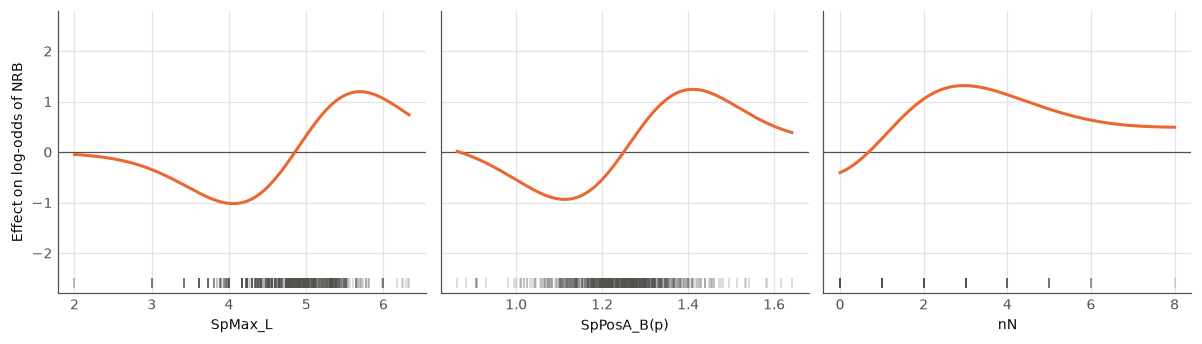

In [13]:
final_k3 = sel[(sel.set == "k3") & (sel.fold == "final (all 844)")]["descriptors"].iloc[0].split(", ")
GAMMA, LAM = 0.3, 10.0
idx = [DESCRIPTORS.index(c) for c in final_k3]
mu, sd_ = X_dev.mean(0), np.maximum(X_dev.std(0, ddof=1), 1e-12)
Z = (X_dev - mu) / sd_
Ks = [np.exp(-GAMMA * (Z[:, j][:, None] - Z[:, j][None, :]) ** 2) for j in idx]
K = sum(Ks)

# Kernel logistic regression by Newton / IRLS (same as the project scripts)
n, y = len(y_dev), y_dev.astype(float)
alpha, b = np.zeros(n), 0.0
obj = lambda a, b: np.sum(np.logaddexp(0, K @ a + b) - y * (K @ a + b)) + 0.5 * LAM * a @ K @ a
for _ in range(100):
    eta = K @ alpha + b
    p = 1 / (1 + np.exp(-eta)); w = np.clip(p * (1 - p), 1e-10, None); rhs = w * eta + (y - p)
    A = np.zeros((n + 1, n + 1)); A[:n, :n] = w[:, None] * K + LAM * np.eye(n)
    A[:n, n] = w; A[n, :n] = w @ K; A[n, n] = w.sum()
    sol = np.linalg.solve(A, np.r_[rhs, rhs.sum()])
    old = obj(alpha, b); alpha, b = sol[:n], sol[n]
    if abs(old - obj(alpha, b)) < 1e-10 * max(1, abs(old)):
        break
print(f"training AUC {auc(1 / (1 + np.exp(-(K @ alpha + b))), y_dev):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, name, j, Kj in zip(axes, final_k3, idx, Ks):
    grid = np.linspace(X_dev[:, j].min(), X_dev[:, j].max(), 300)
    gz = (grid - mu[j]) / sd_[j]
    f = np.exp(-GAMMA * (gz[:, None] - Z[:, j][None, :]) ** 2) @ alpha
    f -= (Kj @ alpha).mean()
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.plot(grid, f, color=COLOR["Additive kernel"], lw=2)
    ax.plot(X_dev[:, j], np.full(n, -2.6), "|", color=MUTED, ms=6, alpha=0.25)   # where chemicals lie
    ax.set_xlabel(name)
    ax.tick_params(length=0)
axes[0].set_ylabel("Effect on log-odds of NRB")
axes[0].set_ylim(-2.8, 2.8)
fig.tight_layout()
plt.show()

Read these at the level of chemical properties (report, *What the descriptors carry*): SpMax_L
stands for **size and branching**, SpPosA_B(p) for **composition** (polarizability), and nN for
**nitrogen content**.

## 9. Summary

- **The flexible models agree on a ceiling** of about 0.85, 0.92, 0.93 and 0.94 AUC at k = 3, 5, 10 and
  all 41; Nadaraya–Watson, a pure local average, sits 0.01–0.03 below it.
- **The cost of readability grows with the budget.** Axis-aligned trees (OCT, CART) stay at 0.79–0.84
  AUC, so their gap widens to about 0.11 with all 41; ridge logistic regression stays within 0.01–0.02
  of the ceiling from k = 10.
- **k = 3:** the additive kernel model, which picks its own descriptors, is the best model (AUC 0.878,
  184 RB cleared at 90% NRB recall against 157 for any model on the fixed list).
- **k = 5:** OCT-H nearly matches the flexible models for screening (210 cleared against 202–217).
- **k ≥ 10:** ridge logistic regression is the readable choice.
- **Caveats:** cross-validation only (test untouched); AUC gaps below ~0.02 are within fold-to-fold
  spread; the additive model's descriptor choice is proven optimal only at k = 3.
  See the report's *Limits* section.